In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing import image

In [ ]:
BASE_DRIVE="/content/drive/MyDrive"

In [ ]:
archive_path=os.path.join(BASE_DRIVE,"archive","archive")
dataset_path=os.path.join(BASE_DRIVE,"dataset","dataset")

In [ ]:
final_dataset="/content/oral_dataset"
train_dir=os.path.join(final_dataset,"train")
val_dir=os.path.join(final_dataset,"validation")
test_dir=os.path.join(final_dataset,"test")
classes=["cancer","normal"]

In [ ]:
for split in ["train","validation","test"]:
    for cls in classes:
        os.makedirs(os.path.join(final_dataset,split,cls),exist_ok=True)

In [ ]:
cancer_images=[]
normal_images=[]

In [ ]:
archive_folders=[os.path.join(archive_path,"Oral cancer Dataset 2.0","OC Dataset kaggle new"),
                 os.path.join(archive_path,"Oral Cancer","Oral Cancer Dataset")]
for folder in archive_folders:
    cancer_folder=os.path.join(folder,"CANCER")
    normal_folder=os.path.join(folder,"NON CANCER")
    if os.path.exists(cancer_folder):
        for file in os.listdir(cancer_folder):
            cancer_images.append(os.path.join(cancer_folder,file))
    if os.path.exists(normal_folder):
        for file in os.listdir(normal_folder):
            normal_images.append(os.path.join(normal_folder,file))

In [ ]:
dataset_cancer=os.path.join(dataset_path,"Oral Cancer photos")
dataset_normal=os.path.join(dataset_path,"normal")
if os.path.exists(dataset_cancer):
    for file in os.listdir(dataset_cancer):
        cancer_images.append(os.path.join(dataset_cancer,file))
if os.path.exists(dataset_normal):
    for file in os.listdir(dataset_normal):
        normal_images.append(os.path.join(dataset_normal,file))
print("Total Cancer Images:",len(cancer_images))
print("Total Normal Images:",len(normal_images))

Total Cancer Images: 1718
Total Normal Images: 1254


In [ ]:
random.shuffle(cancer_images)
random.shuffle(normal_images)

In [ ]:
def split_data(images):
    total=len(images)
    train_split=int(0.7*total)
    val_split=int(0.85*total)
    train=images[:train_split]
    val=images[train_split:val_split]
    test=images[val_split:]
    return train,val,test
cancer_train,cancer_val,cancer_test=split_data(cancer_images)
normal_train,normal_val,normal_test=split_data(normal_images)

In [ ]:
def copy_files(files,destination):
    for file in files:
        try:
            shutil.copy(file,destination)
        except:
            pass

copy_files(cancer_train,os.path.join(train_dir,"cancer"))
copy_files(cancer_val,os.path.join(val_dir,"cancer"))
copy_files(cancer_test,os.path.join(test_dir,"cancer"))

copy_files(normal_train,os.path.join(train_dir,"normal"))
copy_files(normal_val,os.path.join(val_dir,"normal"))
copy_files(normal_test,os.path.join(test_dir,"normal"))

print("Dataset Prepared Successfully!")

Dataset Prepared Successfully!


In [ ]:
from PIL import Image
def remove_corrupted_images(folder_path):
    removed=0
    for root,dirs,files in os.walk(folder_path):
        for file in files:
            file_path=os.path.join(root, file)
            try:
                img=Image.open(file_path)
                img.verify()
            except Exception:
                print("Removing corrupted image:",file_path)
                os.remove(file_path)
                removed+=1
    print(f"\nTotal corrupted images removed: {removed}")
remove_corrupted_images(final_dataset)


Total corrupted images removed: 0


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
train_datagen=ImageDataGenerator(preprocessing_function=preprocess_input,rotation_range=15,zoom_range=0.15,width_shift_range=0.1,
height_shift_range=0.1,horizontal_flip=True)
val_datagen=ImageDataGenerator(preprocessing_function=preprocess_input)
train_generator=train_datagen.flow_from_directory(train_dir,target_size=(224,224),batch_size=16,class_mode='binary',shuffle=True)
validation_generator=val_datagen.flow_from_directory(val_dir,target_size=(224,224),batch_size=16,class_mode='binary',shuffle=False)
test_generator=val_datagen.flow_from_directory(test_dir,target_size=(224,224),batch_size=16,class_mode='binary',shuffle=False)

Found 1142 images belonging to 2 classes.
Found 396 images belonging to 2 classes.
Found 390 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.layers import BatchNormalization
base_model=EfficientNetB0(weights='imagenet',include_top=False,input_shape=(224,224,3))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
base_model.trainable=False
model=Sequential([base_model,GlobalAveragePooling2D(),BatchNormalization(),Dense(256,activation='relu'),Dropout(0.3),
Dense(128,activation='relu'),Dropout(0.2),Dense(1,activation='sigmoid')])
model.compile(optimizer=Adam(learning_rate=0.0003),loss='binary_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,415,652 (16.84 MB)

 Trainable params: 363,521 (1.39 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
early_stop=EarlyStopping(monitor='val_accuracy',patience=5,restore_best_weights=True)
reduce_lr=ReduceLROnPlateau(monitor='val_loss',factor=0.3,patience=2,verbose=1)
checkpoint=ModelCheckpoint("/content/best_model.h5",monitor='val_accuracy',save_best_only=True,verbose=1)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
class_weights=compute_class_weight(class_weight='balanced',classes=np.unique(train_generator.classes),y=train_generator.classes)
class_weights=dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(0.8744257274119449), 1: np.float64(1.1676891615541922)}


In [ ]:
history=model.fit(train_generator,validation_data=validation_generator,epochs=20,callbacks=[early_stop,reduce_lr,checkpoint],
class_weight=class_weights)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7333 - loss: 0.5616

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch 1: val_accuracy improved from None to 0.89141, saving model to /content/best_model.h5



Epoch 1: finished saving model to /content/best_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.8047 - loss: 0.4600 - val_accuracy: 0.8914 - val_loss: 0.3478 - learning_rate: 3.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8435 - loss: 0.3457
Epoch 2: val_accuracy improved from 0.89141 to 0.90404, saving model to /content/best_model.h5



Epoch 2: finished saving model to /content/best_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.8485 - loss: 0.3298 - val_accuracy: 0.9040 - val_loss: 0.2778 - learning_rate: 3.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8965 - loss: 0.2565
Epoch 3: val_accuracy improved from 0.90404 to 0.92424, saving model to /content/best_model.h5


...


Epoch 4: finished saving model to /content/best_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.9081 - loss: 0.2364 - val_accuracy: 0.9369 - val_loss: 0.1812 - learning_rate: 3.0000e-04
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9155 - loss: 0.2120
Epoch 5: val_accuracy did not improve from 0.93687
72/72 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.9133 - loss: 0.2121 - val_accuracy: 0.9318 - val_loss: 0.1772 - learning_rate: 3.0000e-04
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9284 - loss: 0.1639
Epoch 6: val_accuracy improved from 0.93687 to 0.94697, saving model to /content/best_model.h5



Epoch 6: finished saving model to /content/best_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.9291 - loss: 0.1692 - val_accuracy: 0.9470 - val_loss: 0.1459 - learning_rate: 3.0000e-04
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9326 - loss: 0.1918
Epoch 7: val_accuracy did not improve from 0.94697
72/72 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.9343 - loss: 0.1865 - val_accuracy: 0.9470 - val_loss: 0.1590 - learning_rate: 3.0000e-04
Epoch 8/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9152 - loss: 0.2055
Epoch 8: val_accuracy improved from 0.94697 to 0.95707, saving model to /content/best_model.h5



Epoch 8: finished saving model to /content/best_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.9194 - loss: 0.1916 - val_accuracy: 0.9571 - val_loss: 0.1259 - learning_rate: 3.0000e-04
Epoch 9/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9476 - loss: 0.1446
Epoch 9: val_accuracy improved from 0.95707 to 0.96212, saving model to /content/best_model.h5



Epoch 9: finished saving model to /content/best_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.9518 - loss: 0.1398 - val_accuracy: 0.9621 - val_loss: 0.1176 - learning_rate: 3.0000e-04
Epoch 10/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9444 - loss: 0.1446
Epoch 10: val_accuracy did not improve from 0.96212
72/72 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.9378 - loss: 0.1604 - val_accuracy: 0.9545 - val_loss: 0.1174 - learning_rate: 3.0000e-04
Epoch 11/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9521 - loss: 0.1399
Epoch 11: val_accuracy did not improve from 0.96212
72/72 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.9457 - loss: 0.1439 - val_accuracy: 0.9571 - val_loss: 0.1123 - learning_rate: 3.0000e-04
Epoch 12/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9417 - loss: 0.1312
Epoch 12: val_accuracy improved from 0.96212 to 0.96465, saving model to /content/best_model.h5



Epoch 12: finished saving model to /content/best_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.9396 - loss: 0.1400 - val_accuracy: 0.9646 - val_loss: 0.1109 - learning_rate: 3.0000e-04
Epoch 13/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9257 - loss: 0.1595
Epoch 13: val_accuracy did not improve from 0.96465
72/72 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9413 - loss: 0.1426 - val_accuracy: 0.9646 - val_loss: 0.0993 - learning_rate: 3.0000e-04
Epoch 14/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9529 - loss: 0.1239
Epoch 14: val_accuracy did not improve from 0.96465
72/72 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.9588 - loss: 0.1121 - val_accuracy: 0.9596 - val_loss: 0.1100 - learning_rate: 3.0000e-04
Epoch 15/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9530 - loss: 0.1122
Epoch 15: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.

Epoch 15: val_accuracy did not improve from 0.96465
72/72 ━━━━━━━━━━━━━━━━━

In [ ]:
base_model.trainable=True
for layer in base_model.layers[:150]:
    layer.trainable=False
model.compile(optimizer=Adam(learning_rate=0.00001),loss='binary_crossentropy',metrics=['accuracy'])
history_fine=model.fit(train_generator,validation_data=validation_generator,epochs=15,callbacks=[early_stop,reduce_lr,checkpoint],
class_weight=class_weights)

Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8097 - loss: 0.4796
Epoch 1: val_accuracy did not improve from 0.96465
72/72 ━━━━━━━━━━━━━━━━━━━━ 225s 3s/step - accuracy: 0.8144 - loss: 0.4635 - val_accuracy: 0.9520 - val_loss: 0.1493 - learning_rate: 1.0000e-05
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8460 - loss: 0.3714
Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.

Epoch 2: val_accuracy did not improve from 0.96465
72/72 ━━━━━━━━━━━━━━━━━━━━ 185s 3s/step - accuracy: 0.8494 - loss: 0.3638 - val_accuracy: 0.9318 - val_loss: 0.2166 - learning_rate: 1.0000e-05
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8440 - loss: 0.3888
Epoch 3: val_accuracy did not improve from 0.96465
72/72 ━━━━━━━━━━━━━━━━━━━━ 194s 3s/step - accuracy: 0.8433 - loss: 0.3833 - val_accuracy: 0.8990 - val_loss: 0.2598 - learning_rate: 3.0000e-06
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8636 - loss: 0.3363
Epoch

In [ ]:
loss,accuracy=model.evaluate(test_generator)
print("\nTest Accuracy:",accuracy*100)

25/25 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.9410 - loss: 0.1698

Test Accuracy: 94.10256147384644


In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import numpy as np
predictions=model.predict(test_generator)
y_pred=(predictions>0.5).astype(int)
print(confusion_matrix(test_generator.classes,y_pred))
print(classification_report(test_generator.classes, y_pred))

25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step
[[206  18]
 [  5 161]]
              precision    recall  f1-score   support

           0       0.98      0.92      0.95       224
           1       0.90      0.97      0.93       166

    accuracy                           0.94       390
   macro avg       0.94      0.94      0.94       390
weighted avg       0.94      0.94      0.94       390



In [ ]:
model.save("/content/oral_cancer_model.h5")
print("Model Saved Successfully!")

Model Saved Successfully!


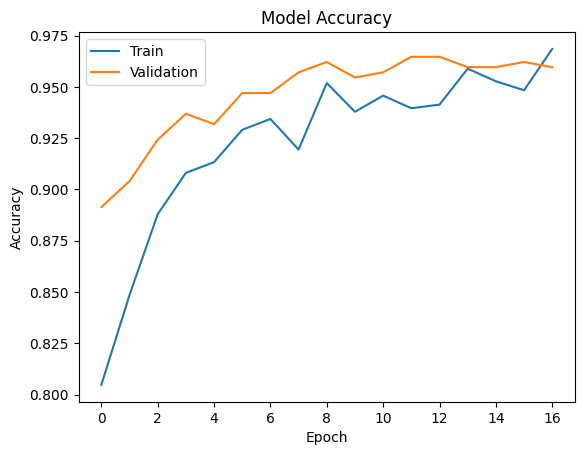

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train','Validation'])
plt.show()

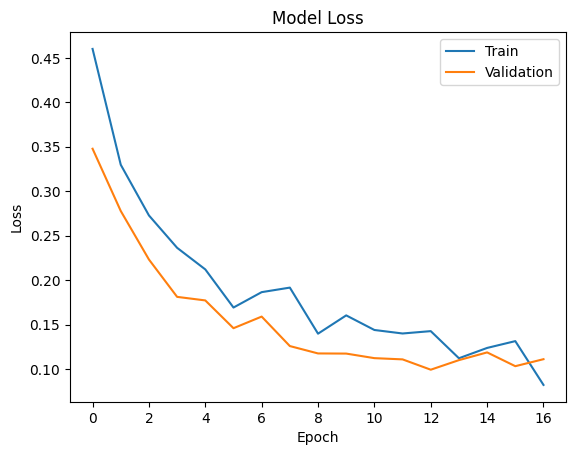

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train','Validation'])
plt.show()

In [ ]:
print(train_generator.class_indices)

{'cancer': 0, 'normal': 1}


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
test_image_path="/content/images.jpg"
img=image.load_img(test_image_path,target_size=(224,224))
img_array=image.img_to_array(img)
img_array=preprocess_input(img_array)
img_array=np.expand_dims(img_array,axis=0)
prediction=model.predict(img_array)
pred_value=prediction[0][0]
print("\nRaw Prediction Value:",pred_value)
if pred_value<0.5:
    cancer_percentage=(1-pred_value)*100
    print(f"\nRESULT: ORAL CANCER DETECTED")
    print(f"Cancer Confidence: {cancer_percentage:.2f}%")
    if cancer_percentage < 60:
        print("Risk Level: LOW RISK")
    elif cancer_percentage < 85:
        print("Risk Level: MEDIUM RISK")
    else:
        print("Risk Level: HIGH RISK")
else:

    normal_percentage=pred_value*100
    print("\nRESULT: NORMAL / NO CANCER")
    print(f"Normal Confidence: {normal_percentage:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step

Raw Prediction Value: 0.99947876

RESULT: NORMAL / NO CANCER
Normal Confidence: 99.95%


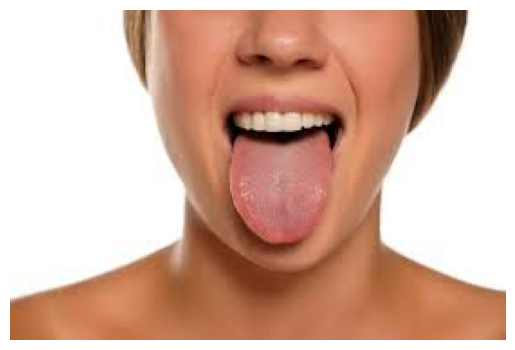

In [ ]:
img_display=plt.imread(test_image_path)
plt.imshow(img_display)
plt.axis('off')
plt.show()